Fn: 556.76 Hz)


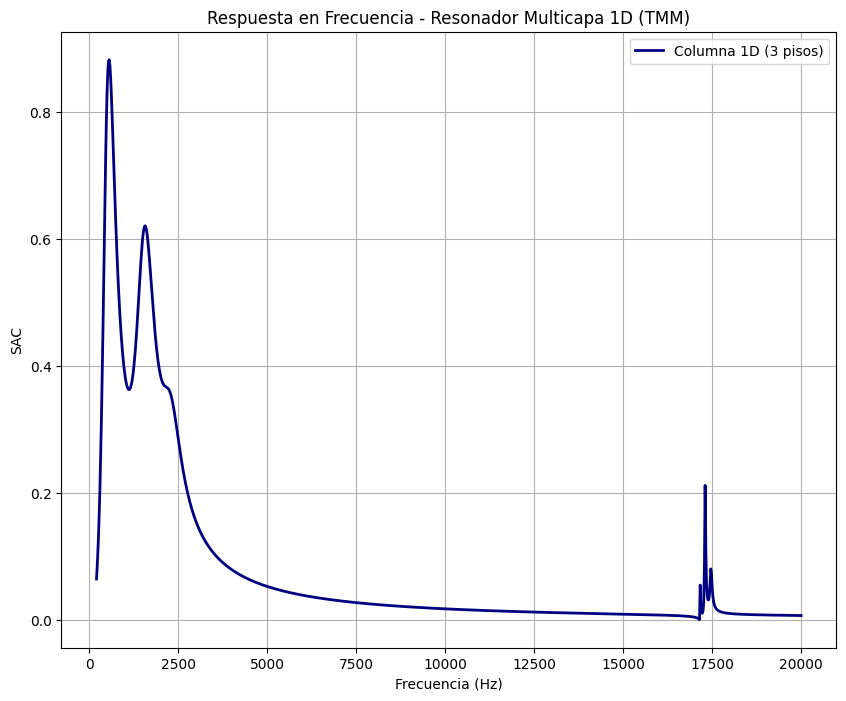

In [12]:
import numpy as np
import matplotlib.pyplot as plt

#Constantes del aire en condiciones normales
rho0 = 1.205 # kg/m^3
c0 = 343.0 # m/s
eta = 1.81e-5 # Pa*s
Z0 = rho0 * c0 #~413.3 Pa*s/m

# celda unitaria 1D (columna de 3 niveles)
A_celda = 64.0      
t_septo = 1.2     
d0 = 1.1          
D_capas = [10.0, 10.0, 10.0]  

freqs = np.linspace(200, 20000, 1000)
w = 2.0 * np.pi * freqs
k0 = w / c0
n = len(freqs)

# A. Impedancia del poro (Maa con corrección empírica de sepia - Li et al., 2023)
d_m = d0 * 1e-3
t_m = t_septo * 1e-3
sigma = (np.pi * (d0 / 2.0)**2) / A_celda
k = d_m * np.sqrt(rho0 * w / (4.0 * eta))
Rs = 0.5 * np.sqrt(2.0 * eta * rho0 * w)

eps = 6.0 - 26.0 * d0 + 40.0 * (d0**2)
delta = (0.8 * d0 + 0.45) * (d0 / t_septo)

R = (32.0 * eta * t_m / (d_m**2 * sigma)) * (np.sqrt(1.0 + (k**2 / 32.0)) + 2.0 * eps * Rs)
X = (w * rho0 * t_m / sigma) * (1.0 + 1.0 / np.sqrt(9.0 + (k**2 / 2.0)) + delta * (d_m / t_m))
Zp = R + 1j * X

#Matriz de transferencia de la columna (3 capas en serie)
TT = np.zeros((n, 2, 2), dtype=complex)
for i in range(n):
    TT[i] = np.eye(2)

for D_mm in D_capas:
    D = D_mm * 1e-3
    for i in range(n):
        Tp = np.array([[1.0, Zp[i]], [0.0, 1.0]], dtype=complex)
        Tc = np.array([[np.cos(k0[i] * D), 1j * Z0 * np.sin(k0[i] * D)],
                       [1j * np.sin(k0[i] * D) / Z0, np.cos(k0[i] * D)]], dtype=complex)
        TT[i] = TT[i] @ Tp @ Tc

#Impedancia con condición de fondo rígido (u = 0)
zt = (TT[:, 0, 0] / TT[:, 1, 0]) / Z0

#SAC
r = np.real(zt)
x = np.imag(zt)
alpha = (4.0 * r) / ((1.0 + r)**2 + x**2)

# Frecuencia
idx_pico = np.argmax(alpha)
fn_1D = freqs[idx_pico]
print(f"Fn: {fn_1D:.2f} Hz)")

plt.figure(figsize=(10, 8))
plt.plot(freqs, alpha, color='navy', lw=2, label='Columna 1D (3 pisos)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('SAC')
plt.title('Respuesta en Frecuencia - Resonador Multicapa 1D (TMM)')
plt.grid(True)
plt.legend()
plt.show()